In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
import copy
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = '/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[18]

In [203]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values )

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]


Randomly selected eid: /Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2/ff4187b5-4176-4e39-8894-53a24b7cf36b
cosmos
CNU          947
CTXsp        124
Isocortex    532
OLF          155
root         321
dtype: int64


In [212]:
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim, n_conditions,beta,sigma_rec=0.):
        super(RNN, self).__init__()

        self.n = n
        self.input_dim = input_dim
        self.n_conditions = n_conditions
        self.beta = beta
        self.sigma_rec = sigma_rec
        self.activation = torch.nn.Softplus(beta =self.beta)

        # Hidden dynamics
        self.recurrent_layer = nn.Linear(self.n+self.input_dim, self.n+self.input_dim, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=1, std=0)
        self.recurrent_layer.bias.requires_grad = True

        self.x0_layer =nn.Sequential(nn.Linear(self.n_conditions, self.n+self.input_dim),nn.ReLU(),
                                     nn.Linear(self.n+self.input_dim, self.n+self.input_dim),nn.ReLU(),
                                     nn.Linear(self.n+self.input_dim, self.n+self.input_dim, bias=True))

        self.alpha= .05
        self.tau =  torch.nn.Parameter(torch.ones(self.n+self.input_dim))
        self.tau.requires_grad = False
        # Dynamics
    def forward(self,conditions, steps):
        """
        :param x0:
        :param conditions:
        :param steps:
        :return:
        """
        t = steps
        #states = self.x0_layer(conditions.int()+1)
        states = torch.nn.Softplus()(self.x0_layer(conditions)[:,None,:])
        #states = self.x0
        recurrent_noise = self.sigma_rec * torch.empty(conditions.shape[0], t, self.n+self.input_dim).normal_(
            mean=0,std=1)
       # inputs = []
        for i in range(t - 1):
            state_new = (1 - self.alpha/self.tau) * states[:, i, :] + 1/self.tau * self.alpha * (
                self.activation(self.recurrent_layer(states[:, i, :])  ) + states[:, i, :]*recurrent_noise[:,i,:] )
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states#, torch.stack(inputs)


In [213]:
#########################################################################
########################### Fit RNN to data  ############################
#########################################################################

condition_matrix_train = torch.tensor(condition_matrix_train).float()
condition_train = torch.mean(condition_matrix_train,dim = 0)
y_train = torch.tensor(response_matrix_train).float()
y_train = torch.mean(y_train,dim = 0)


y_train = (y_train - torch.mean(y_train, dim=(0, 1),keepdims=True)) / torch.std(y_train,dim=(0, 1),keepdims=True)

rnn = RNN(n = y_train.shape[2], input_dim = 5, n_conditions = condition_train.shape[1],beta=20,sigma_rec=0.)
epochs  = 1000
steps = 100
my_dataset = TensorDataset(y_train,condition_train)  # create your datset
my_dataloader = DataLoader(my_dataset, batch_size=128,shuffle=False)
optimizer = torch.optim.Adam(rnn.parameters(), lr=.001, weight_decay=0.001)

#rnn.recurrent_layer.bias.data[:rnn.n] = torch.FloatTensor(target_mean)

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_81259/1740139682.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  condition_matrix_train = torch.tensor(condition_matrix_train).float()


In [219]:

epoch = 0
while epoch < epochs:

    for batch_idx, (y_batch,conditions_batch) in enumerate(my_dataloader):
        optimizer.zero_grad()
        x_batch = rnn.forward(conditions_batch, steps)

        x_batch = x_batch[:,:,:rnn.n]
        reg_loss = 1* torch.std(torch.std(x_batch, dim=[0, 1])) + \
            1 * torch.std(torch.mean(x_batch, dim=[0, 1]))

        center = torch.mean(x_batch,dim = (0,1))
        scale = torch.std(x_batch,dim = (0,1))
        x_batch  = (x_batch - center)/(scale)



        # Compute mean squared error for each neuron normalized by the variance in that neuron
        loss = 1*torch.nn.MSELoss()(x_batch, y_batch)+.1*torch.mean((torch.mean(x_batch,dim=(0,1)) - 1)**2)
        loss.backward()
        optimizer.step()
        #self.recurrent_layer.bias.data = torch.nn.ReLU()(self.recurrent_layer.bias.data)
        #self.alpha.data = torch.nn.Softplus()(self.alpha.data)
        epoch += 1

        if epoch % 10 == 0:

            print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
            print("loss: {:.4f}".format(loss.item()))
            #writer.
            #add_scalar('Loss/test', loss.item(), epoch)

Epoch: 10/1000............. loss: 0.5724
Epoch: 20/1000............. loss: 0.5462
Epoch: 30/1000............. loss: 0.5285
Epoch: 40/1000............. loss: 0.5079
Epoch: 50/1000............. loss: 0.4924
Epoch: 60/1000............. loss: 0.5299
Epoch: 70/1000............. loss: 0.4853
Epoch: 80/1000............. loss: 0.4596
Epoch: 90/1000............. loss: 0.4439
Epoch: 100/1000............. loss: 0.4273
Epoch: 110/1000............. loss: 0.4166
Epoch: 120/1000............. loss: 0.3962
Epoch: 130/1000............. loss: 0.3813
Epoch: 140/1000............. loss: 0.3633
Epoch: 150/1000............. loss: 0.3526
Epoch: 160/1000............. loss: 0.3415
Epoch: 170/1000............. loss: 0.3359
Epoch: 180/1000............. loss: 0.3227
Epoch: 190/1000............. loss: 0.3330
Epoch: 200/1000............. loss: 0.3155
Epoch: 210/1000............. loss: 0.3015
Epoch: 220/1000............. loss: 0.3054
Epoch: 230/1000............. loss: 0.2912
Epoch: 240/1000............. loss: 0.2811


KeyboardInterrupt: 

In [276]:
def calculate_gain(rnn,conditions,steps,epsilon):

        # Simulate RNN
        x = rnn.forward(conditions,steps)

        # Z-score
       # x = (x - torch.mean(x, dim=(0, 1))) / torch.std(x,dim=(0, 1))
        h = torch.abs(torch.diff(x,dim=1)/(x[:,:-1,:]+epsilon))
        g = torch.mean(h,dim=(0,1))
        return g

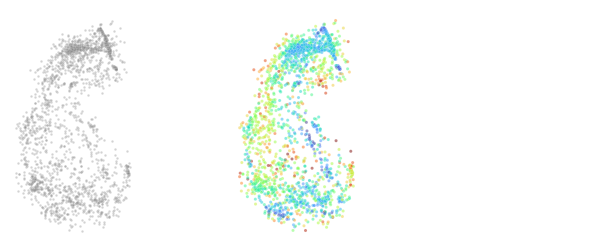

In [243]:
####################################################################
#################### DensMap plot for fit RNN ######################
####################################################################

from sklearn.manifold import TSNE
#g = perturbed_rnn.calculate_gain(condition_train,100,20).detach()



#x = rnn(condition_train,100).detach()
rnn.alpha = .05
x = rnn(torch.FloatTensor(np.linspace(-1,1,100))[:,None],100).detach()
x = x[:,:,:rnn.n]
x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
#x = x  + 2*(2*torch.rand_like(x)-1)

x = x.detach().numpy()
g =  calculate_gain(rnn,condition_train,steps,10).detach()

fit = umap.UMAP(n_components = 2,densmap = True, dens_lambda =1 ,n_neighbors = 200)
x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()
#pca = PCA(n_components=2).fit(x.reshape(-1,x.shape[2]).T)
#x_proj = pca.transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo',hue_norm=(.001,.01))

#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =mag[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


In [274]:
print("Simulating RNN...")

x = rnn(torch.FloatTensor(np.linspace(-1,1,200))[:,None],200).detach()
rnn.alpha = .025
#x = (x-torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
x = x.detach().numpy()

print("Fitting PCA...")
pca = PCA().fit(x.reshape(-1,x.shape[2]))

Simulating RNN...
Fitting PCA...


In [293]:
# Plot curvature
##########################################
########## Plotting manifolds ############
##########################################


#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))



print("Creating dataframe...")

x = torch.tensor(x).float()
#x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))

h = rnn.recurrent_layer(x)
flow_field = -x + rnn.activation(h)

e = torch.exp(10* h)
b=e/(1+e)**2
#b = stable_sigmoid_derivative(beta*h)
w_rec =  rnn.recurrent_layer.weight.data.detach()
curvature =  rnn.beta*(flow_field.detach() @ w_rec.t())**2 * b
#curvature = b

Creating dataframe...


/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_81259/2892267746.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x = torch.tensor(x).float()


In [304]:
rows = []
for trial in range(x.shape[0]):
    trajectory = x[trial,:,:]
    proj_trajectory = pca.transform(trajectory)
    for t in range(x.shape[1]):
        rows.append({'t': t,
             'trial': trial,
             'x': proj_trajectory[t,0],
             'y': proj_trajectory[t,1],
             'z': proj_trajectory[t,2],

             'c': torch.linalg.norm(curvature[trial,t,np.argsort(g)[-20]]).item()
                     })

new_df = pd.DataFrame(rows)
x.shape

torch.Size([200, 200, 2069])

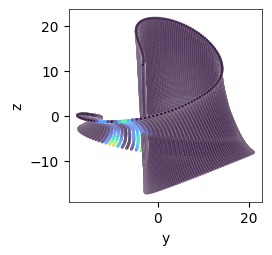

In [305]:
fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax0=fig.add_subplot(gs[0,0])


sns.scatterplot(data = new_df, x = 'y', y = 'z', hue = 'c',palette = 'turbo',s=4,legend=False,alpha = .5,ax=ax0,lw=.1)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(False)
plt.savefig('Figures/Figure_boundary_8.jpg',
        format='jpeg',
        dpi=450,
        bbox_inches='tight', transparent=True)
# ax.spines['left'].set_color('black')
# ax.spines['bott
# om'].set_color('black')


In [301]:
new_df.c.max()

2.420605182647705

(-0.0640594299766235, 1.3694007251760922)

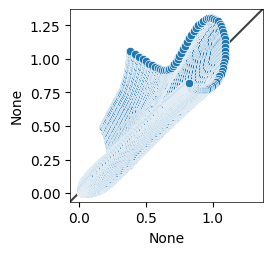

In [249]:
x = rnn(torch.FloatTensor(np.linspace(-1,1,100))[:,None],100).detach()
h = rnn.recurrent_layer(x)
f=rnn.activation(h).detach()
neuron = np.argsort(g)[3]
fig = plt.figure(figsize=(2.5,2.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)

ax=fig.add_subplot(gs[0,0])
sns.scatterplot(y = f[:,:,neuron].flatten(),x = x[:,:,neuron].detach().flatten(),ax=ax)
lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

# now plot both limits against eachother
ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0)
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)

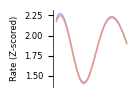

In [270]:

neuron = np.argsort(g)[1]

# x =rnn.forward(condition_train, steps=100)[:,:,:rnn.n]
# #x = rnn.observation_layer(x)
# x = (x-torch.mean(x,dim=(0,1), keepdim=True))/torch.std(x,dim=(0,1), keepdim=True)
rows = []
for trial in range(condition_train.shape[0]):
    for t in range(response_matrix_train.shape[2]):
        rows.append({'condition': condition_train[trial,:].item(),
                         'trial': trial,
                         't':t,
                         'x': x[trial, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==-1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [189]:
5g[np.argsort(g)[-1]]

tensor(0.0210)